### Testing different p values by changing data points 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import linregress

spring = pd.read_csv("../../data/ratios_VHF_spring.csv")
summer = pd.read_csv("../../data/ratios_VHF_summer.csv")

### Original Linear Regressions

In [2]:
# Strip whitespace from headers so that the column names are consistent.
spring = spring.rename(columns=lambda column: column.strip())
summer = summer.rename(columns=lambda column: column.strip())

grain_size_columns = ["coarse_sand", "fine_sand", "silt", "clay"]
season_data = {"Spring": spring, "Summer": summer}

regression_rows = []
for season, data in season_data.items():
    for grain_size in grain_size_columns:
        valid = data[["VHF", grain_size]].dropna()
        if len(valid) < 3 or valid["VHF"].nunique() < 2:
            regression_rows.append({
                "season": season,
                "grain_size": grain_size,
                "n": len(valid),
                "slope": np.nan,
                "intercept": np.nan,
                "r_squared": np.nan,
                "p_value": np.nan,
            })
            continue

        regression = linregress(valid["VHF"], valid[grain_size])
        regression_rows.append({
            "season": season,
            "grain_size": grain_size,
            "n": len(valid),
            "slope": regression.slope,
            "intercept": regression.intercept,
            "r_squared": regression.rvalue ** 2,
            "p_value": regression.pvalue,
        })

regression_results = pd.DataFrame(regression_rows)
regression_results

,season,grain_size,n,slope,intercept,r_squared,p_value
0,Spring,coarse_sand,7,-1.779493,-0.148915,0.857034,0.002770
1,Spring,fine_sand,7,-1.974403,0.019691,0.543938,0.058508
2,Spring,silt,7,-2.301857,-0.048167,0.551370,0.055915
3,Spring,clay,7,-2.525609,-0.055886,0.550982,0.056048
4,Summer,coarse_sand,5,-1.767383,-0.427664,0.255416,0.385073
5,Summer,fine_sand,5,-1.935042,-0.052390,0.743931,0.059918
6,Summer,silt,5,-0.962597,0.133020,0.404051,0.249070
7,Summer,clay,5,-1.432234,0.014055,0.423289,0.234488


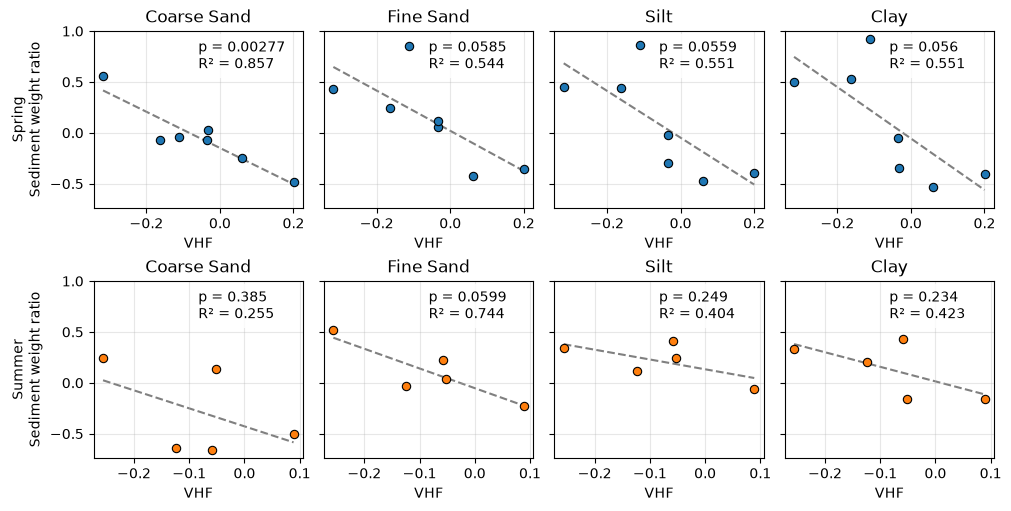

In [3]:
fig, axes = plt.subplots(
    nrows=len(season_data),
    ncols=len(grain_size_columns),
    figsize=(10, 5),
    sharey=True,
    constrained_layout=True,
)

colors = {"Spring": "tab:blue", "Summer": "tab:orange"}
for row, (season, data) in enumerate(season_data.items()):
    for column, grain_size in enumerate(grain_size_columns):
        ax = axes[row, column]
        valid = data[["VHF", grain_size]].dropna()
        result = regression_results[
            (regression_results["season"] == season)
            & (regression_results["grain_size"] == grain_size)
        ].iloc[0]

        ax.scatter(
            valid["VHF"],
            valid[grain_size],
            color=colors[season],
            edgecolor="black",
            linewidth=0.8,
            zorder=2,
        )
        if pd.notna(result["slope"]):
            x_line = np.linspace(valid["VHF"].min(), valid["VHF"].max(), 100)
            ax.plot(
                x_line,
                result["intercept"] + result["slope"] * x_line,
                color="grey",
                linewidth=1.5,
                zorder=1,
                linestyle="--",
            )
            annotation = f"p = {result['p_value']:.3g}\nR² = {result['r_squared']:.3f}"
        else:
            annotation = "Insufficient data"

        ax.text(
            0.5,
            0.95,
            annotation,
            transform=ax.transAxes,
            ha="left",
            va="top",
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
        )
        ax.set_title(grain_size.replace("_", " ").title())
        ax.set_xlabel("VHF")
        ax.grid(alpha=0.3)
        if column == 0:
            ax.set_ylabel(f"{season}\nSediment weight ratio")

plt.show()

### Testing seasonal differences of regression slope and intercept

In [4]:
from scipy.stats import t
from statsmodels.stats.multitest import multipletests

# Compare Spring and Summer with one model per grain-size class:
# y = intercept + VHF + season + VHF:season.
# The season:VHF term tests slope differences. The season term tests
# intercept differences at VHF = 0 (the same point used by linregress).
comparison_rows = []
for grain_size in grain_size_columns:
    spring_valid = spring[["VHF", grain_size]].dropna().assign(season=0)
    summer_valid = summer[["VHF", grain_size]].dropna().assign(season=1)
    valid = pd.concat([spring_valid, summer_valid], ignore_index=True)

    if len(valid) < 5 or valid["VHF"].nunique() < 2:
        comparison_rows.append({
            "grain_size": grain_size,
            "n": len(valid),
            "slope_difference": np.nan,
            "slope_p_value": np.nan,
            "intercept_difference": np.nan,
            "intercept_p_value": np.nan,
        })
        continue

    x = valid["VHF"].to_numpy(dtype=float)
    y = valid[grain_size].to_numpy(dtype=float)
    season = valid["season"].to_numpy(dtype=float)
    design = np.column_stack((np.ones(len(valid)), x, season, x * season))
    coefficients, _, _, _ = np.linalg.lstsq(design, y, rcond=None)
    residuals = y - design @ coefficients
    degrees_of_freedom = len(y) - design.shape[1]

    if degrees_of_freedom <= 0:
        comparison_rows.append({
            "grain_size": grain_size,
            "n": len(valid),
            "slope_difference": np.nan,
            "slope_p_value": np.nan,
            "intercept_difference": np.nan,
            "intercept_p_value": np.nan,
        })
        continue

    residual_variance = np.sum(residuals ** 2) / degrees_of_freedom
    covariance = residual_variance * np.linalg.inv(design.T @ design)
    standard_errors = np.sqrt(np.diag(covariance))

    # Coefficient order: intercept, VHF slope, season effect, season-by-VHF effect.
    intercept_difference = coefficients[2]
    slope_difference = coefficients[3]
    intercept_t = intercept_difference / standard_errors[2]
    slope_t = slope_difference / standard_errors[3]

    comparison_rows.append({
        "grain_size": grain_size,
        "n": len(valid),
        "slope_difference": slope_difference,
        "slope_p_value": 2 * t.sf(abs(slope_t), degrees_of_freedom),
        "intercept_difference": intercept_difference,
        "intercept_p_value": 2 * t.sf(abs(intercept_t), degrees_of_freedom),
    })

comparison_results = pd.DataFrame(comparison_rows)

# Correct each family of four grain-size tests for multiple comparisons.
for p_column, adjusted_column in [
    ("slope_p_value", "slope_p_value_holm"),
    ("intercept_p_value", "intercept_p_value_holm"),
]:
    valid_p = comparison_results[p_column].notna()
    comparison_results.loc[valid_p, adjusted_column] = multipletests(
        comparison_results.loc[valid_p, p_column],
        method="holm",
    )[1]

comparison_results["slope_significant"] = (
    comparison_results["slope_p_value_holm"] < 0.05
)
comparison_results["intercept_significant"] = (
    comparison_results["intercept_p_value_holm"] < 0.05
)
comparison_results


,grain_size,n,slope_difference,slope_p_value,intercept_difference,intercept_p_value,slope_p_value_holm,intercept_p_value_holm,slope_significant,intercept_significant
0,coarse_sand,12,0.012110,0.993045,-0.278749,0.191833,1.0,0.767331,False,False
1,fine_sand,12,0.039361,0.976624,-0.072081,0.712946,1.0,1.000000,False,False
2,silt,12,1.339261,0.390717,0.181187,0.422455,1.0,1.000000,False,False
3,clay,12,1.093376,0.533596,0.069941,0.781727,1.0,1.000000,False,False
